In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from scipy import stats
pd.set_option('display.max_columns',None)


In [3]:
car_data = pd.read_csv(r"C:\Users\X390\Desktop\UNI\Data Mining\dataset progetto\seller_info_dm1_2627.csv")
car_data.head(6)

maxtheft = car_data['pct_theft_title'].max()
whodat = car_data[car_data['pct_theft_title']==maxtheft]
whodat.loc[:, ['sp_id','seller_rating_class','pct_theft_title']]

,sp_id,seller_rating_class,pct_theft_title
13370,335314.0,high,0.756757


In [9]:
car_data

,sp_id,n_listings,price_median,savings_amount_median,daysonmarket_median,mileage_median,year_median,vehicle_age_median,owner_count_median,horsepower_median,engine_displacement_median,city_fuel_economy_median,highway_fuel_economy_median,back_legroom_median,front_legroom_median,fuel_tank_volume_median,height_median,length_median,width_median,pct_isCab,pct_is_new,pct_salvage,pct_theft_title,n_listing_days,listing_span_days,dominant_body_type,dominant_fuel_type,dominant_transmission,dominant_wheel_system,dominant_listing_color,franchise_status,new_used_profile,seller_rating_class
0,404771.0,30,6700.0,431.0,13.0,193193.5,2011.0,9.0,2.0,258.5,NaN,17.0,23.5,38.65,41.3,21.00,68.9,195.35,77.10,0.133333,0.000000,0.0,0.000000,15,156,suv_crossover,gasoline,a,NaN,gray,independent,used_only,medium
1,336590.0,17,10995.0,505.0,24.0,87589.0,2012.0,7.0,2.0,182.0,2400.0,21.0,28.5,37.30,41.4,15.90,64.7,180.30,72.50,0.058824,0.000000,0.0,0.000000,14,589,suv_crossover,gasoline,a,awd,silver,independent,used_only,medium
2,392016.0,18,7645.0,632.0,43.0,151434.0,2010.5,9.5,2.0,205.0,NaN,20.0,28.5,35.50,41.7,17.50,58.1,188.20,72.00,0.111111,0.000000,0.0,0.000000,15,97,sedan,gasoline,a,NaN,blue,independent,used_only,low
3,294197.0,12,23449.0,479.0,18.0,31186.0,2017.0,3.0,1.0,178.0,2500.0,25.0,35.0,38.65,42.3,16.50,57.9,190.05,72.05,0.000000,0.000000,0.0,0.000000,7,338,sedan,gasoline,a,NaN,unknown,franchise,used_only,medium
4,372085.0,14,8990.0,505.5,213.0,144471.5,2007.5,12.0,1.5,240.0,3500.0,16.0,22.0,36.80,42.3,21.10,70.2,187.60,74.00,0.000000,0.000000,0.0,0.071429,6,315,suv_crossover,gasoline,a,NaN,silver,independent,used_only,medium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13838,59623.0,185,42625.0,0.0,28.0,12.0,2020.0,0.0,1.0,290.0,3500.0,20.0,27.0,36.60,42.0,17.20,65.7,191.45,74.80,0.000000,0.735135,0.0,0.000000,65,369,suv_crossover,gasoline,a,NaN,gray,franchise,mixed,high
13839,49530.0,155,31590.0,0.0,27.0,8.0,2020.0,0.0,1.0,305.0,3600.0,22.0,29.0,39.70,42.3,19.00,67.0,198.40,78.60,0.484848,0.787097,0.0,0.000000,64,370,suv_crossover,gasoline,a,fwd,white,franchise,mixed,medium
13840,49610.0,296,29992.5,0.0,48.0,9.0,2020.0,0.0,1.0,277.0,3300.0,21.0,26.0,38.90,42.2,19.00,69.3,193.40,80.50,0.468468,0.625000,0.0,0.009009,98,393,suv_crossover,gasoline,a,NaN,unknown,franchise,mixed,medium
13841,372531.0,235,32864.0,0.0,51.0,15.0,2020.0,0.0,1.0,285.0,3600.0,19.0,26.0,38.60,41.1,21.10,69.3,193.10,80.00,0.413333,0.685106,0.0,0.013333,71,435,suv_crossover,gasoline,a,NaN,black,franchise,mixed,medium


In [10]:
car_data.loc[0:5, ['sp_id','n_listings']]

,sp_id,n_listings
0,404771.0,30
1,336590.0,17
2,392016.0,18
3,294197.0,12
4,372085.0,14
5,67741.0,103


In [11]:
#Gli attributi discutibili sono questi:

ws = car_data.loc[: ,'pct_isCab' : 'dominant_wheel_system']
ws = ws.rename(columns={"dominant_wheel_system": "d_w_s"})
ws.drop(['dominant_body_type','listing_span_days','n_listing_days','pct_isCab'], axis=1) 


,pct_is_new,pct_salvage,pct_theft_title,dominant_fuel_type,dominant_transmission,d_w_s
0,0.000000,0.0,0.000000,gasoline,a,NaN
1,0.000000,0.0,0.000000,gasoline,a,awd
2,0.000000,0.0,0.000000,gasoline,a,NaN
3,0.000000,0.0,0.000000,gasoline,a,NaN
4,0.000000,0.0,0.071429,gasoline,a,NaN
...,...,...,...,...,...,...
13838,0.735135,0.0,0.000000,gasoline,a,NaN
13839,0.787097,0.0,0.000000,gasoline,a,fwd
13840,0.625000,0.0,0.009009,gasoline,a,NaN
13841,0.685106,0.0,0.013333,gasoline,a,NaN


In [12]:
#categorizziamo e contiamo i valori nelle categorie.
ws.value_counts(['pct_is_new']).reset_index() #Dato abbastanza mantenibile, mostra molta variabilità.


,pct_is_new,count
0,0.000000,7384
1,0.500000,33
2,1.000000,31
3,0.600000,27
4,0.666667,25
...,...,...
4532,0.946309,1
4533,0.945455,1
4534,0.968750,1
4535,0.968085,1


In [13]:
ws.value_counts(['pct_salvage']).reset_index() #Qua invece possiamo tagliare di netto il dato essendo che mostra una enorme maggioranza di zeri.

,pct_salvage,count
0,0.000000,12574
1,0.058824,23
2,0.052632,19
3,0.045455,18
4,0.062500,18
...,...,...
419,0.909091,1
420,0.920000,1
421,0.923077,1
422,0.940000,1


In [14]:
ws.value_counts(['pct_theft_title']).reset_index() #Stesso discorso per i dati eliminati.

,pct_theft_title,count
0,0.000000,11706
1,0.016949,26
2,0.032258,23
3,0.017241,23
4,0.030303,23
...,...,...
450,0.002427,1
451,0.002331,1
452,0.002315,1
453,0.002193,1


In [15]:
car_data["dominant_fuel_type"].value_counts().reset_index #Pare eliminabile

<bound method Series.reset_index of dominant_fuel_type
gasoline             13658
flex_fuel_vehicle       91
diesel                  52
biodiesel               16
hybrid                  13
electric                12
unknown                  1
Name: count, dtype: int64>

In [17]:
dingdong = car_data.loc[:, ["dominant_body_type",'seller_rating_class']].value_counts().reset_index() #Pare eliminabile
dingdong

,dominant_body_type,seller_rating_class,count
0,suv_crossover,medium,5080
1,suv_crossover,high,2207
2,suv_crossover,low,1633
3,sedan,medium,1522
4,sedan,high,871
5,pickup_truck,medium,763
6,sedan,low,651
7,pickup_truck,high,409
8,pickup_truck,low,252
9,coupe,medium,89


([0, 1, 2, 3, 4, 5, 6, 7, 8],
 [Text(0, 0, 'suv_crossover'),
  Text(1, 0, 'sedan'),
  Text(2, 0, 'pickup_truck'),
  Text(3, 0, 'coupe'),
  Text(4, 0, 'hatchback'),
  Text(5, 0, 'van'),
  Text(6, 0, 'convertible'),
  Text(7, 0, 'minivan'),
  Text(8, 0, 'wagon')])

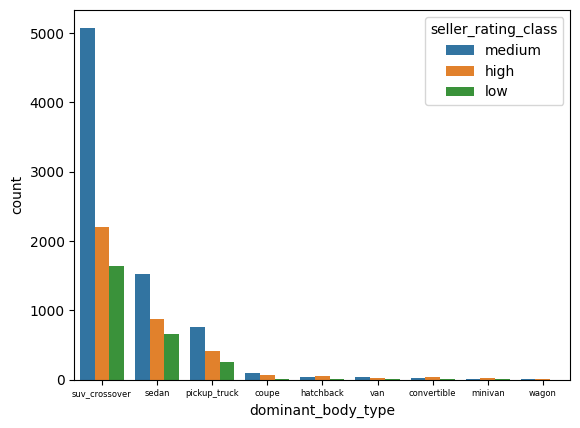

In [20]:

sns.barplot(data=dingdong,y='count', x='dominant_body_type',hue='seller_rating_class')
plt.xticks(size=6)

<h4>Se la maggior parte dei venditori sono medi, le auto saranno in prevalenza di classe media considerando la distribuzione. inoltre c'è troppa disparità tra i crossover e il resto delle auto.</h4>

In [17]:
car_data['owner_count_median'].value_counts().reset_index() #Probabilmente possiamo ignorare quei valori non interi????

,owner_count_median,count
0,1.0,8668
1,2.0,3948
2,3.0,733
3,1.5,219
4,2.5,162
5,4.0,42
6,3.5,23
7,5.0,5
8,4.5,3
9,6.0,1


In [ ]:
car_data['new_used_profile'].value_counts().reset_index()

,new_used_profile,count
0,used_only,7384
1,mixed,6428
2,new_only,31


In [18]:
#Troviamo tutti i NaN per ogni attributo e incolonniamolo in un df.
nulls = car_data.isnull().sum()
nulldf = pd.DataFrame(nulls, columns=["null_values_amount"])
nulldf

,null_values_amount
sp_id,0
n_listings,0
price_median,0
savings_amount_median,0
daysonmarket_median,0
mileage_median,1
year_median,0
vehicle_age_median,1
owner_count_median,39
horsepower_median,6


In [19]:
pricebyseller = pd.DataFrame(car_data.loc[:,['seller_rating_class','price_median']])
pricebyseller
#multi = pd.MultiIndex(car_data['seller_rating_class'].groupby(['low','medium','high']),[0,1,2])
#multi

pricemedian_x_rating = pricebyseller.groupby(['seller_rating_class']).describe().apply(np.sqrt) #Qua i dati in forma logaritmica che suddividono per rating dei venditori confrontando la mediana dei prezzi
pricemedian_x_rating = pricemedian_x_rating.T

In [20]:
def iqr(sr: pd.Series):
    Q1 = sr.quantile(0.25)
    Q3 = sr.quantile(0.75)
    return (Q3-Q1)

def upper(sr: pd.Series):
    upperlimit = sr.quantile(0.75)+(1.5*iqr(sr))
    return upperlimit


def lower(sr: pd.Series):
    lowerlimit = sr.quantile(0.25)-(1.5*iqr(sr))
    return lowerlimit

iqr(car_data['price_median'])
upper(car_data['price_median'])
lower(car_data['price_median'])





np.float64(-13594.5)

In [21]:
pricebyseller.groupby('seller_rating_class').describe()

price_median                                               \
                           count          mean           std     min      25%   
seller_rating_class                                                             
high                      3687.0  22221.937719  17167.101497  2195.0  10950.0   
low                       2579.0  21940.509746  10849.131196  1985.0  12999.0   
medium                    7577.0  23933.145302  13858.636549  1699.0  13000.0   

                                                  
                         50%       75%       max  
seller_rating_class                               
high                 18998.0  28899.25  236438.0  
low                  22124.0  28245.00  114900.0  
medium               23840.5  30890.00  229888.0

In [22]:

#aggreghiamo le dimensioni in una sola variabile.
sumattr = car_data[['height_median','width_median','length_median']]*0.0254 #convertiamo in metri le dimensioni
sumattr

,height_median,width_median,length_median
0,1.75006,1.95834,4.96189
1,1.64338,1.84150,4.57962
2,1.47574,1.82880,4.78028
3,1.47066,1.83007,4.82727
4,1.78308,1.87960,4.76504
...,...,...,...
13838,1.66878,1.89992,4.86283
13839,1.70180,1.99644,5.03936
13840,1.76022,2.04470,4.91236
13841,1.76022,2.03200,4.90474


In [23]:
volume_median = sumattr.prod(axis=1).rename('volume_median') #ora abbiamo le dimensioni in metri cubi. SooS Sees SiiS SaaS
#sumattr.assign(volume_median = lambda x: x.height_median * x.width_median * x.length_median) #Versione più elegante così abbiamo il dataframe con la nuova colonna.
#Vorrei metterlo nel df e cancellare le altre dimensioni. ripuliamo un poino di ose
volume_median.reset_index()


,index,volume_median
0,0,17.005451
1,1,13.859232
2,2,12.901179
3,3,12.992166
4,4,15.969923
...,...,...
13838,13838,15.417838
13839,13839,17.121435
13840,13840,17.680182
13841,13841,17.543112


In [24]:
killcolumns = ['dominant_transmission','dominant_fuel_type','pct_salvage','pct_theft_title','dominant_wheel_system']
c_d_clean = car_data.drop(killcolumns,axis=1)

In [25]:
c_d_clean.insert(19, 'volume_median' , volume_median)

In [26]:
c_d_clean.drop(['height_median','width_median','length_median'],axis=1) #Eccolo bello snellito. 

,sp_id,n_listings,price_median,savings_amount_median,daysonmarket_median,mileage_median,year_median,vehicle_age_median,owner_count_median,horsepower_median,engine_displacement_median,city_fuel_economy_median,highway_fuel_economy_median,back_legroom_median,front_legroom_median,fuel_tank_volume_median,volume_median,pct_isCab,pct_is_new,n_listing_days,listing_span_days,dominant_body_type,dominant_listing_color,franchise_status,new_used_profile,seller_rating_class
0,404771.0,30,6700.0,431.0,13.0,193193.5,2011.0,9.0,2.0,258.5,NaN,17.0,23.5,38.65,41.3,21.00,17.005451,0.133333,0.000000,15,156,suv_crossover,gray,independent,used_only,medium
1,336590.0,17,10995.0,505.0,24.0,87589.0,2012.0,7.0,2.0,182.0,2400.0,21.0,28.5,37.30,41.4,15.90,13.859232,0.058824,0.000000,14,589,suv_crossover,silver,independent,used_only,medium
2,392016.0,18,7645.0,632.0,43.0,151434.0,2010.5,9.5,2.0,205.0,NaN,20.0,28.5,35.50,41.7,17.50,12.901179,0.111111,0.000000,15,97,sedan,blue,independent,used_only,low
3,294197.0,12,23449.0,479.0,18.0,31186.0,2017.0,3.0,1.0,178.0,2500.0,25.0,35.0,38.65,42.3,16.50,12.992166,0.000000,0.000000,7,338,sedan,unknown,franchise,used_only,medium
4,372085.0,14,8990.0,505.5,213.0,144471.5,2007.5,12.0,1.5,240.0,3500.0,16.0,22.0,36.80,42.3,21.10,15.969923,0.000000,0.000000,6,315,suv_crossover,silver,independent,used_only,medium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13838,59623.0,185,42625.0,0.0,28.0,12.0,2020.0,0.0,1.0,290.0,3500.0,20.0,27.0,36.60,42.0,17.20,15.417838,0.000000,0.735135,65,369,suv_crossover,gray,franchise,mixed,high
13839,49530.0,155,31590.0,0.0,27.0,8.0,2020.0,0.0,1.0,305.0,3600.0,22.0,29.0,39.70,42.3,19.00,17.121435,0.484848,0.787097,64,370,suv_crossover,white,franchise,mixed,medium
13840,49610.0,296,29992.5,0.0,48.0,9.0,2020.0,0.0,1.0,277.0,3300.0,21.0,26.0,38.90,42.2,19.00,17.680182,0.468468,0.625000,98,393,suv_crossover,unknown,franchise,mixed,medium
13841,372531.0,235,32864.0,0.0,51.0,15.0,2020.0,0.0,1.0,285.0,3600.0,19.0,26.0,38.60,41.1,21.10,17.543112,0.413333,0.685106,71,435,suv_crossover,black,franchise,mixed,medium


Cerchiamo di fare quei fottuti grafici sick fucks...

In [27]:
#legge di sturges
bins = np.log2(c_d_clean['sp_id'].count()) + 1
bins

np.float64(14.756869011549092)

<Axes: >

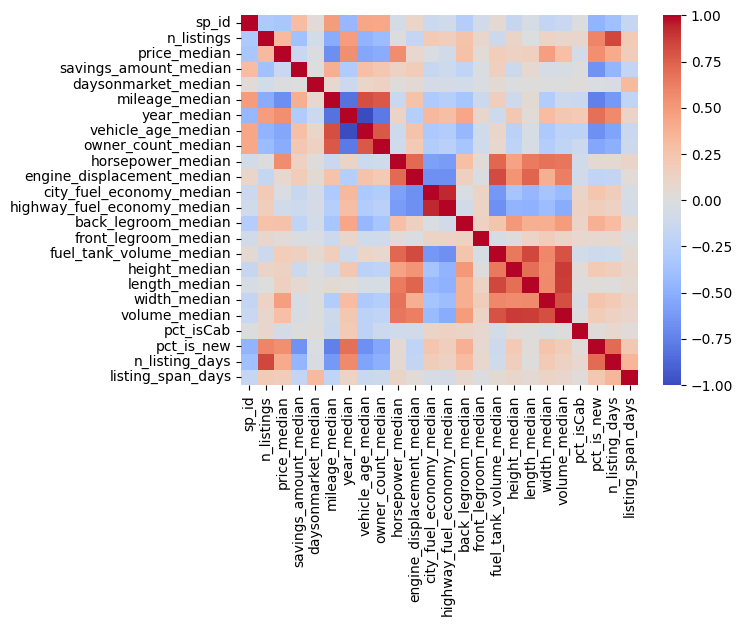

In [28]:
sns.heatmap(c_d_clean.loc[:,'sp_id':'listing_span_days'].corr(method='pearson'),cmap="coolwarm", vmin=-1, vmax=1, annot=False, )

Text(0, 0.5, 'Car Sellers')

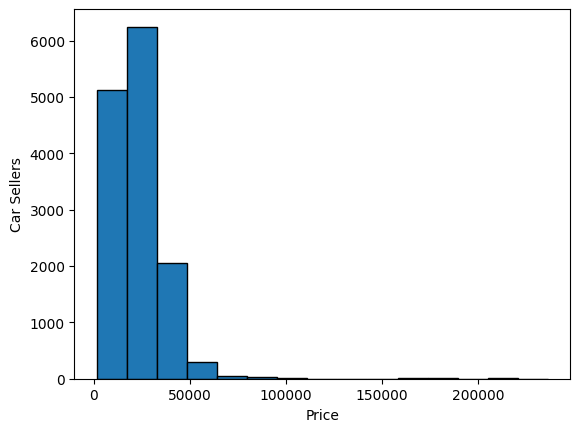

In [29]:



plt.hist(c_d_clean['price_median'],bins=15, edgecolor='black' )
plt.xlabel('Price')
plt.ylabel('Car Sellers')
#Positively skewed - cioè la maggior parte dei venditori vendono a prezzi relativamente bassi. sono presenti degli outliers. Dato abbastanza prevedibile gotta say


count     13843.000000
mean      23106.140357
std       14365.066586
min        1699.000000
25%       12495.000000
50%       22385.000000
75%       29888.000000
max      236438.000000
Name: price_median, dtype: float64

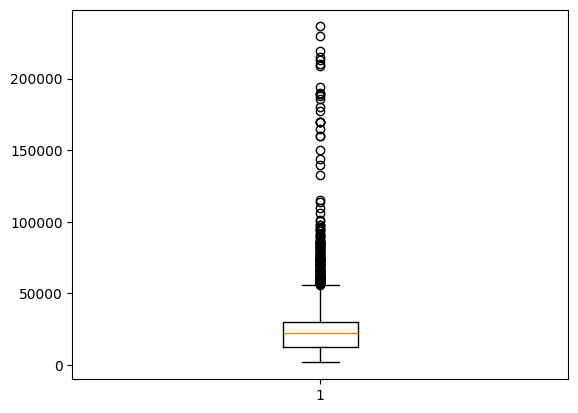

In [30]:
plt.boxplot(c_d_clean['price_median'])
c_d_clean['price_median'].describe()

In [31]:

pricemedian_x_horsepower = c_d_clean.loc[:, ['price_median','seller_rating_class']]
pricemedian_x_horsepower

,price_median,seller_rating_class
0,6700.0,medium
1,10995.0,medium
2,7645.0,low
3,23449.0,medium
4,8990.0,medium
...,...,...
13838,42625.0,high
13839,31590.0,medium
13840,29992.5,medium
13841,32864.0,medium


In [32]:

pricemedian_x_horsepower.groupby('seller_rating_class').split()
pricemedian_x_horsepower


AttributeError: 'DataFrameGroupBy' object has no attribute 'split'

(-99.35, 550.0)

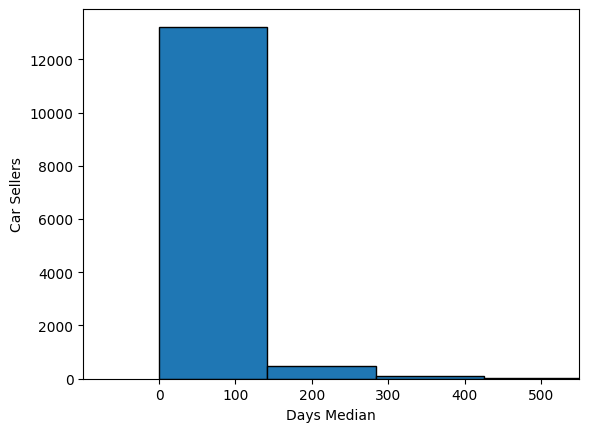

In [33]:
plt.hist(c_d_clean['daysonmarket_median'],bins=14, edgecolor='black', )
plt.xlabel('Days Median')
plt.ylabel('Car Sellers')
plt.xlim(right=550)


In [34]:
#Proviamo a dividere i concessionari per rating class e per categoria usato/nuovo/entrambe, facendo un boxplot

rating_x_new = car_data.loc[:, ['seller_rating_class','new_used_profile']]
bars = rating_x_new.groupby('seller_rating_class').value_counts().reset_index()
bars



,seller_rating_class,new_used_profile,count
0,high,used_only,2351
1,high,mixed,1326
2,high,new_only,10
3,low,mixed,1342
4,low,used_only,1228
5,low,new_only,9
6,medium,used_only,3805
7,medium,mixed,3760
8,medium,new_only,12


C:\Users\X390\AppData\Local\Temp\ipykernel_18300\280375039.py:1: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x="seller_rating_class", y="count", hue="new_used_profile", data=bars, ci=None)


Text(0.5, 0, 'Rating Classes')

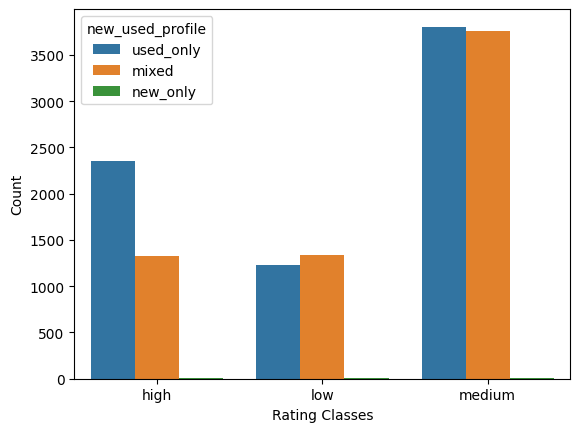

In [35]:
sns.barplot(x="seller_rating_class", y="count", hue="new_used_profile", data=bars, ci=None)
plt.ylabel('Count')
plt.xlabel('Rating Classes')


<bold><h3>Il Grafico mostra una discrepanza tra concessionari di "usato esclusivo" e "misto usato e nuovo" esclusivamente nel caso di concessionari di livello alto, suggerendo che i concessionari di successo vendano tipicamente solo auto usate.</h3></bold><br>
<h3>Inoltre si vede a colpo d'occhio che concessionari che vendono esclusivamente Nuovo sono pressoché inesistenti nel dataset.</h3>




In [36]:
mileage = pd.DataFrame(car_data['mileage_median'])
mileage


,mileage_median
0,193193.5
1,87589.0
2,151434.0
3,31186.0
4,144471.5
...,...
13838,12.0
13839,8.0
13840,9.0
13841,15.0



242251.875

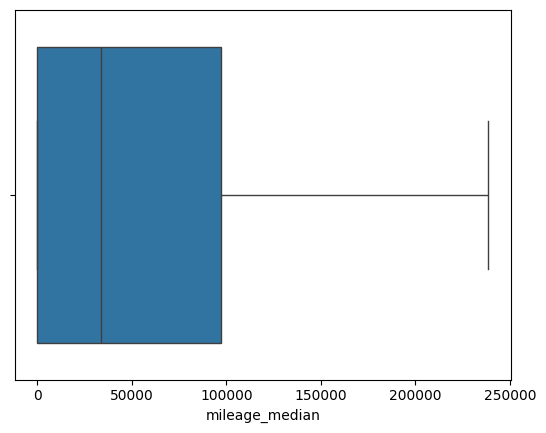

In [37]:
sns.boxplot(x='mileage_median', data=mileage)
plt.show()


<h3>La maggior parte delle maccchine presenti sul dataset ha un Migliaggio tra 100k e 250k; Non ci sono outliers. Osserviamo un eventuale correlazione tra migliaggio e prezzo</h3>

In [38]:
mileage_x_price = car_data.loc[:, ['mileage_median','price_median']]
m_x_p_clean = mileage_x_price[mileage_x_price['price_median']<=upper(mileage_x_price['price_median'])]


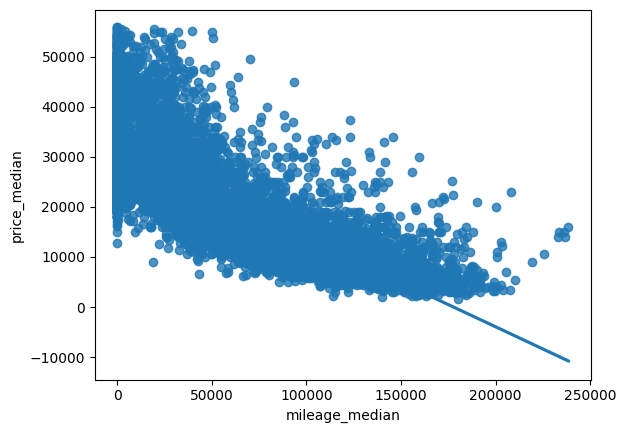

In [39]:
sns.regplot(x="mileage_median",y="price_median", fit_reg=True, data=m_x_p_clean)

plt.show()
#Outliers da ripulire sul prezzo


<h3>Correlazione inversa, sembra più che ovvio, vediamo la distribuzione di prezzo.</h3>

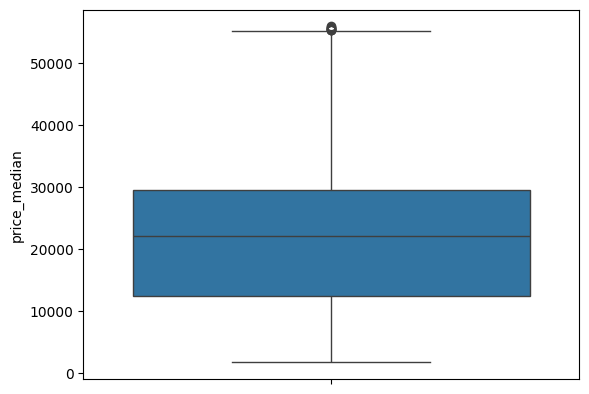

In [40]:
sns.boxplot(data=m_x_p_clean['price_median'])
plt.show()

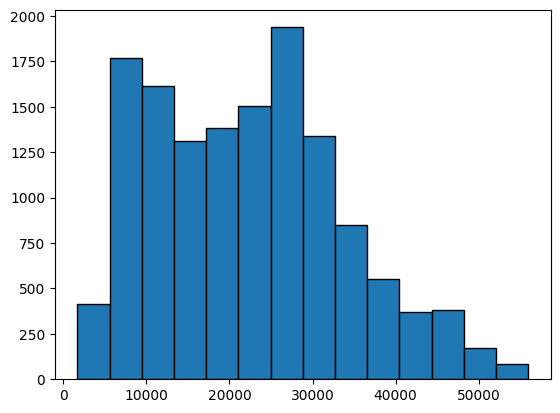

In [41]:
plt.hist(m_x_p_clean['price_median'], bins=14, edgecolor="black")
plt.show()

In [42]:
# Rapporto tra rating e prezzo pulito dagli outliers.
r_p_clean = pricebyseller[pricebyseller['price_median'] <=upper(pricebyseller['price_median'])]


<h3>Si vede che la distribuzione è bimodale, bisognerebbe cercare di dividere questa distribuzione in categorie per estrapolare le due distribuzioni</h3>

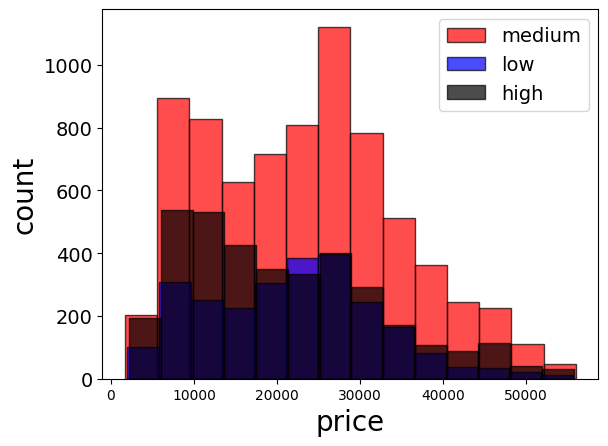

In [43]:
#Istogramma a categorie di rating class con distribuzioni di prezzo

vals = list(r_p_clean['seller_rating_class'].unique())
colors = ['red','blue','black']
for i, val in enumerate(vals):
    plt.hist(r_p_clean[r_p_clean['seller_rating_class']==val]['price_median'], color=colors[i], edgecolor='black',label=val, alpha=0.7, bins=14)

plt.legend(loc='best', fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=14)
plt.xlabel("price", fontsize=20)
plt.ylabel("count", fontsize=20)
# plt.grid(alpha=0.3)
plt.show()

<h3>Sembra che non ci sia una grossa influenza del prezzo sul livello del concessionario.</h3>

<p style="font-size:17">Si nota che le distribuzioni non sono normali, le distribuzioni per rating basso e medio sono bimodali. la distribuzione più informativa è quella media, semplicemente per mole di dati disponibili.<br>
Quasi tutti gli outliers curiosamente facevano parte della classe alta, il che suggerisce una correlazione tra prezzo e classe alta abbastanza solida, o al minimo che i concessionari che vendono veicoli di alto valore sono generalmente di successo.</p>

In [54]:
x = np.array(r_p_clean[r_p_clean['seller_rating_class']=='high']['price_median'])

shapiro = stats.shapiro(x)
shapiro.pvalue

np.float64(4.771262690966317e-35)